In [1]:
#IMPORT LIBS
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import numpy.ma as ma
import matplotlib.ticker as mticker

# Path to your .ttf
font_path = "/home/links/mf671/times.ttf"

# Add the font to Matplotlib's font manager
fm.fontManager.addfont(font_path)

# Get the name of the font inside the .ttf
font_name = fm.FontProperties(fname=font_path).get_name()

# Set as default
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Point
from datetime import timedelta
import cartopy.util as cutil
#import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats
import pandas as pd

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

In [2]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking
#!cdo selmon,6,7,8 ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_jja_1940-2023.nc
!ls

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking
block_clim_DAV_GHA_JJA_DJF.png
composite.svg
dictionaries
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_notyrlis_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_notyrlis_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023.nc


In [3]:
#IMPORT DATASET
ds = xr.open_dataset('ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_jja_1940-2023.nc')
ds_comp = xr.open_dataset('../precipitation/tp_2.5x2.5_northem_daily_jja_1940-2023_new.nc')
ds_comp = ds_comp.rename({'valid_time': 'time'})
ds = ds.assign_coords(time=ds['time'].dt.floor('D'))
ds_comp = ds_comp.assign_coords(time=ds_comp['time'].dt.floor('D'))
ds_ucomp = xr.open_dataset('../winds/ERA5_u_northem_daily_850hPa_2.5x2.5_jja_1940-2023.nc')
ds_ucomp = ds_ucomp.rename({'valid_time': 'time'}).assign_coords(time=ds['time'].dt.floor('D'))
ds_vcomp = xr.open_dataset('../winds/ERA5_v_northem_daily_850hPa_2.5x2.5_jja_1940-2023.nc').assign_coords(time=ds['time'].dt.floor('D'))
#store variables for the composite
GHA = ds['GHA_tracked']
zg = ds['zg']/9.8
ucomp = ds_ucomp['u'][:,0,:,:]
vcomp = ds_vcomp['v'][:,0,:,:-1]
anom = ds_comp['tp']*1000 #converted to mm/day
lat = ds['lat']
lon = ds['lon']
times = ds['time']

In [4]:
print(anom.shape,ucomp.shape)

(7728, 37, 144) (7728, 37, 144)


In [5]:
def Bootstrap(zg,n_sample,n_iter):
    length = len(zg)
    zg_set = []
    for iter in range(n_iter):
        #print(np.arange(0,length,1))
        idxs = np.random.choice(np.arange(0,length,1), size=n_sample, replace=False)
        zg_set.append(zg[idxs,:,:].mean(axis=0))
    return np.array(zg_set).std(axis=0)

#we subtract to the anom field the annual mean in order to have only deviations from the annual mean and remove the seasonal cycle
dates = []
for time in times:
    if str(time.values)[0:4] == '1940':
        dates.append(str(time.values)[5:10])
    else:
        break
usual_year = np.zeros((len(dates),37,144))
for i,date in tqdm(enumerate(dates)):
    for t,time in enumerate(times):
        if str(time.values)[5:10] == date:
            usual_year[i,:,:] += anom[t,:,:]
usual_year = usual_year/len(dates)
usual_year_repeat = np.repeat(usual_year, 84, axis = 0)
anom = anom - usual_year_repeat

In [15]:
#compute the composites
plon,plat = -70,70 #Greenland Blocking
#plon,plat = 10,55 #European Blocking

series = GHA.loc[:,plat,plon]
list_retrograding = []
list_an_retrograding = []
list_u_retrograding = []
list_v_retrograding = []
list_upstream = []
list_an_upstream = []
list_u_upstream = []
list_v_upstream = []
#summer
labels_retrograding = [8, 17, 74, 80, 107, 108, 113, 147, 151, 176, 178, 188, 190, 228, 259, 265, 267, 271, 306, 309, 310, 349, 382, 388, 409, 415, 422, 453, 460, 536, 570, 573, 645, 653, 685, 692, 725, 728, 731, 766, 769, 775, 809, 842, 849, 881, 883, 890, 916, 924, 960, 961, 963, 999, 1080, 1085, 1127, 1130, 1131, 1165, 1168, 1172, 1204, 1243, 1245, 1276, 1279, 1283, 1318, 1319, 1328, 1356, 1362, 1393, 1396, 1403, 1428, 1434, 1467, 1469, 1477, 1504, 1513, 1546, 1550, 1552, 1591, 1620, 1623, 1630, 1663, 1664, 1667, 1668, 1692, 1695, 1705, 1738, 1772, 1780, 1783, 1807, 1810, 1813, 1814, 1849, 1881, 1887, 1892, 1921, 1922, 1957, 1959, 1991, 1992, 2030, 2039, 2064, 2067, 2071, 2101, 2102, 2107, 2110, 2116, 2187, 2194, 2228, 2233, 2271, 2275, 2280, 2281, 2314, 2318, 2350, 2353, 2362, 2387, 2435, 2464, 2471, 2472, 2496, 2499, 2504, 2529, 2532, 2570, 2610, 2616, 2622, 2651, 2660, 2700, 2735, 2743, 2766, 2777, 2779, 2813, 2838, 2882, 2915, 2922, 2923, 2989, 2995, 2997, 2996, 3038, 3040, 3065, 3066, 3073, 3074, 3077, 3116, 3118, 3121, 3153, 3162, 3184]
labels_upstream = [13, 44, 103, 104, 146, 182, 185, 220, 222, 225, 230, 268, 312, 347, 354, 384, 386, 414, 498, 502, 508, 540, 543, 545, 577, 611, 615, 616, 621, 649, 687, 688, 776, 804, 802, 841, 844, 887, 918, 926, 955, 958, 997, 998, 1032, 1039, 1083, 1087, 1088, 1122, 1124, 1126, 1171, 1206, 1241, 1278, 1287, 1286, 1291, 1320, 1323, 1324, 1392, 1395, 1431, 1509, 1516, 1549, 1583, 1629, 1634, 1665, 1670, 1697, 1698, 1734, 1742, 1744, 1773, 1775, 1845, 1847, 1848, 1853, 1883, 1889, 1920, 1924, 1925, 1954, 1960, 1997, 2032, 2072, 2074, 2149, 2191, 2193, 2197, 2230, 2231, 2273, 2279, 2315, 2320, 2356, 2358, 2388, 2395, 2428, 2429, 2434, 2468, 2498, 2535, 2536, 2539, 2572, 2611, 2617, 2618, 2658, 2692, 2693, 2704, 2706, 2705, 2737, 2740, 2806, 2810, 2815, 2840, 2846, 2848, 2876, 2880, 2884, 2921, 2928, 2960, 2963, 2991, 3034, 3036, 3078, 3109, 3110, 3148, 3156, 3186, 3188, 3190, 3192]
print(len(times))
for t,time in tqdm(enumerate(times)):
    if series[t] in labels_retrograding:#in list_west:
        list_retrograding.append(zg.loc[time,:,:].values)
        list_an_retrograding.append(anom.loc[time,:,:].values)
        list_u_retrograding.append(ucomp.loc[time,:,:].values)
        list_v_retrograding.append(vcomp.loc[time,:,:].values)
    if series[t] in labels_upstream:#in list_west:
        list_upstream.append(zg.loc[time,:,:].values)
        list_an_upstream.append(anom.loc[time,:,:].values)
        list_u_upstream.append(ucomp.loc[time,:,:].values)
        list_v_upstream.append(vcomp.loc[time,:,:].values)


7728


7728it [01:33, 83.04it/s]


In [17]:
N_days_retrograding = len(list_retrograding)
sum_t_retrograding = sum(list_retrograding)
sum_an_retrograding = sum(list_an_retrograding)
zg_comp_retrograding = sum_t_retrograding/len(list_retrograding)
anom_comp_retrograding = sum_an_retrograding/len(list_an_retrograding)
u_comp_retrograding = sum(list_u_retrograding)/len(list_u_retrograding)
v_comp_retrograding = sum(list_v_retrograding)/len(list_v_retrograding)
t_st_anom_retrograding = abs(anom_comp_retrograding/Bootstrap(anom,len(list_an_retrograding),1000)) > 2
N_days_upstream = len(list_upstream)
sum_t_upstream = sum(list_upstream)
sum_an_upstream = sum(list_an_upstream)
zg_comp_upstream = sum_t_upstream/len(list_upstream)
anom_comp_upstream = sum_an_upstream/len(list_an_upstream)
u_comp_upstream = sum(list_u_upstream)/len(list_u_upstream)
v_comp_upstream = sum(list_v_upstream)/len(list_v_upstream)
t_st_anom_upstream = abs(anom_comp_upstream/Bootstrap(anom,len(list_an_upstream),1000)) > 2

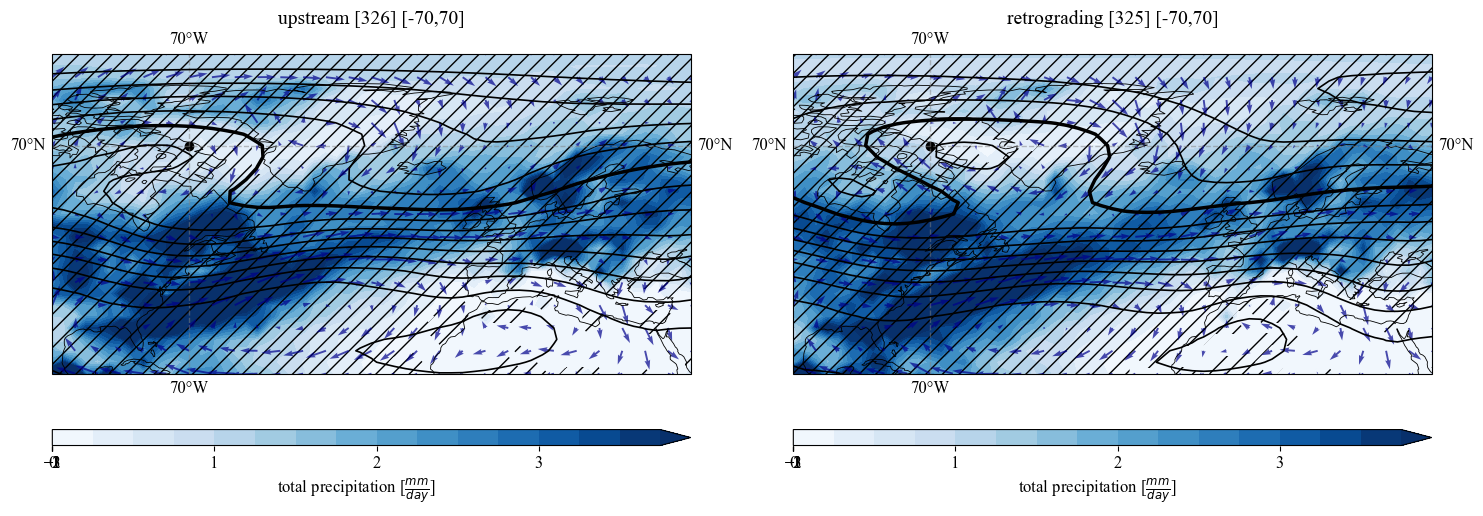

In [22]:
fig,ax = plt.subplots(nrows=1,ncols=2,figsize=(15,6),subplot_kw={'projection': ccrs.PlateCarree()})

#FIRST PLOT
title = 'upstream [' + str(N_days_upstream) + '] [' + str(plon) + ',' + str(plat) + ']' 
field = ma.masked_array(zg_comp_upstream,zg_comp_upstream==0)
anom_comp = anom_comp_upstream
extent =[-100,40,20,90] #Greenland
#extent =[-180,180,20,90] #Europe
ax[0].set_extent(extent, ccrs.PlateCarree())
ax[0].coastlines(linewidth = 0.6)
ax[0].plot(plon,plat,color='black', marker='o')
gl = ax[0].gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')
gl.xlocator = mticker.FixedLocator([plon])
gl.ylocator = mticker.FixedLocator([plat])
gl.xlabels_top = False
gl.ylabels_left = False
cont = ax[0].contour(lon,lat,field,
                    colors = 'black',
                    alpha =1.,
                    linewidths = 1.2,
                    levels = np.arange(4600,7200,40)
                    )
cont2=ax[0].contour(lon,lat,field,
                    colors = 'black',
                    alpha =1.,
                    linewidths = 2.5,
                    levels = [5600]
                    )
                    #cmap = "YlGnBu")
#c_range = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/8)) + np.array(np.amax(abs(anom_comp))/16)
c_range = np.arange(0,4,0.25)
#ticks = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/4)) + np.array(np.amax(abs(anom_comp))/8)
c_range = np.arange(0,4,0.25)
shadings = ax[0].contourf(lon,lat,anom_comp,
                      cmap='Blues',
                      extend = 'max', 
                      levels = c_range)
cs_p = ax[0].contourf(lon,lat,t_st_anom_upstream,levels = 1,colors='none',hatches=['','//'])
fig.colorbar(shadings,ticks=ticks,label=r'total precipitation [$\frac{mm}{day}$]',pad=0.1,orientation='horizontal',shrink=1,aspect=40)
stride = 2  # plot every 3rd gridpoint, adjust as needed
ax[0].quiver(lon[::stride], lat[::stride],
             u_comp_upstream[::stride, ::stride],
             v_comp_upstream[::stride, ::stride],
             transform=ccrs.PlateCarree(),
             scale=200,        # adjust to make arrows bigger/smaller
             width=0.003,
             color='darkblue',
             alpha=0.7)
ax[0].set_title(title)

# SECOND PLOT
title = 'retrograding [' + str(N_days_retrograding) + '] [' + str(plon) + ',' + str(plat) + ']'
field = ma.masked_array(zg_comp_retrograding,zg_comp_retrograding==0)
anom_comp = anom_comp_retrograding
extent =[-100,40,20,90] #Greenland
#extent =[-180,180,20,90] #Europe
ax[1].set_extent(extent, ccrs.PlateCarree())
ax[1].coastlines(linewidth = 0.6)
ax[1].plot(plon,plat,color='black', marker='o')
gl = ax[1].gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')
gl.xlocator = mticker.FixedLocator([plon])
gl.ylocator = mticker.FixedLocator([plat])
gl.xlabels_top = False
gl.ylabels_left = False
cont = ax[1].contour(lon,lat,field,
                    colors = 'black',
                    alpha =1.,
                    linewidths = 1.2,
                    levels = np.arange(4600,7200,40)
                    )
cont2=ax[1].contour(lon,lat,field,
                    colors = 'black',
                    alpha =1.,
                    linewidths = 2.5,
                    levels = [5600]
                    )
                    #cmap = "YlGnBu")
#c_range = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/8)) + np.array(np.amax(abs(anom_comp))/16)
c_range = np.arange(0,4,0.25)
#ticks = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/4)) + np.array(np.amax(abs(anom_comp))/8)
c_range = np.arange(0,4,0.25)
shadings = ax[1].contourf(lon,lat,anom_comp,
                      cmap='Blues',
                      extend = 'max', 
                      levels = c_range)
cs_p = ax[1].contourf(lon,lat,t_st_anom_retrograding,levels = 1,colors='none',hatches=['','//'])
fig.colorbar(shadings,ticks=ticks,label=r'total precipitation [$\frac{mm}{day}$]',pad=0.1,orientation='horizontal',shrink=1,aspect=40)
# Add this after the cs_p line in SECOND PLOT (before ax[1].set_title)
ax[1].quiver(lon[::stride], lat[::stride],
             u_comp_retrograding[::stride, ::stride],
             v_comp_retrograding[::stride, ::stride],
             transform=ccrs.PlateCarree(),
             scale=200,
             width=0.003,
             color='darkblue',
             alpha=0.7)
ax[1].set_title(title)

plt.tight_layout()
#plt.savefig('/Users/michelefilippucci/PLOTS/pres_exeter/winter_composite_greenland_latent_hear_west.png',dpi=300)


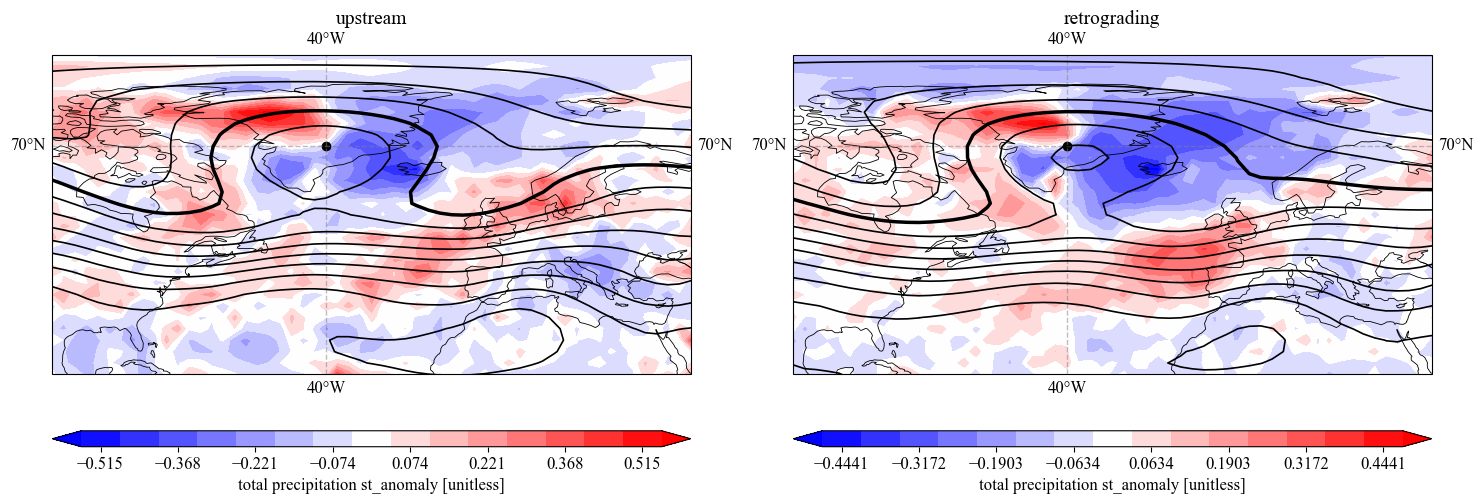

In [8]:
fig,ax = plt.subplots(nrows=1,ncols=2,figsize=(15,6),subplot_kw={'projection': ccrs.PlateCarree()})

#FIRST PLOT
title = 'upstream'
field = ma.masked_array(zg_comp_upstream,zg_comp_upstream==0)
anom_comp = anom_comp_upstream/np.std(anom,axis=0)
extent =[-100,40,20,90] #Greenland
#extent =[-180,180,20,90] #Europe
ax[0].set_extent(extent, ccrs.PlateCarree())
ax[0].coastlines(linewidth = 0.6)
ax[0].plot(plon,plat,color='black', marker='o')
gl = ax[0].gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')
gl.xlocator = mticker.FixedLocator([plon])
gl.ylocator = mticker.FixedLocator([plat])
gl.xlabels_top = False
gl.ylabels_left = False
cont = ax[0].contour(lon,lat,field,
                    colors = 'black',
                    alpha =1.,
                    linewidths = 1.2,
                    levels = np.arange(4600,7200,40)
                    )
cont2=ax[0].contour(lon,lat,field,
                    colors = 'black',
                    alpha =1.,
                    linewidths = 2.5,
                    levels = [5600]
                    )
                    #cmap = "YlGnBu")
c_range = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/8)) + np.array(np.amax(abs(anom_comp))/16)
#c_range = np.arange(-85,86,10)
ticks = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/4)) + np.array(np.amax(abs(anom_comp))/8)
#ticks = np.arange(-85,86,10)
shadings = ax[0].contourf(lon,lat,anom_comp,
                      cmap='bwr',
                      extend = 'both', 
                      levels = c_range)
#cs_p = ax[0].contourf(lon,lat,t_st_anom,levels = 1,colors='none',hatches=['','//'])
fig.colorbar(shadings,ticks=ticks,label=r'total precipitation st_anomaly [unitless]',pad=0.1,orientation='horizontal',shrink=1,aspect=40)
ax[0].set_title(title)

# SECOND PLOT
title = 'retrograding'
field = ma.masked_array(zg_comp_retrograding,zg_comp_retrograding==0)
anom_comp = anom_comp_retrograding/np.std(anom,axis=0)
extent =[-100,40,20,90] #Greenland
#extent =[-180,180,20,90] #Europe
ax[1].set_extent(extent, ccrs.PlateCarree())
ax[1].coastlines(linewidth = 0.6)
ax[1].plot(plon,plat,color='black', marker='o')
gl = ax[1].gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')
gl.xlocator = mticker.FixedLocator([plon])
gl.ylocator = mticker.FixedLocator([plat])
gl.xlabels_top = False
gl.ylabels_left = False
cont = ax[1].contour(lon,lat,field,
                    colors = 'black',
                    alpha =1.,
                    linewidths = 1.2,
                    levels = np.arange(4600,7200,40)
                    )
cont2=ax[1].contour(lon,lat,field,
                    colors = 'black',
                    alpha =1.,
                    linewidths = 2.5,
                    levels = [5600]
                    )
                    #cmap = "YlGnBu")
c_range = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/8)) + np.array(np.amax(abs(anom_comp))/16)
#c_range = np.arange(-85,86,10)
ticks = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/4)) + np.array(np.amax(abs(anom_comp))/8)
#ticks = np.arange(-85,86,10)
shadings = ax[1].contourf(lon,lat,anom_comp,
                      cmap='bwr',
                      extend = 'both', 
                      levels = c_range)
#cs_p = ax[1].contourf(lon,lat,t_st_anom,levels = 1,colors='none',hatches=['','//'])
fig.colorbar(shadings,ticks=ticks,label=r'total precipitation st_anomaly [unitless]',pad=0.1,orientation='horizontal',shrink=1,aspect=40)
ax[1].set_title(title)

plt.tight_layout()
#plt.savefig('/Users/michelefilippucci/PLOTS/pres_exeter/winter_composite_greenland_latent_hear_west.png',dpi=300)
